# VaDeSC on simulated data (multi-seed)

Similar setup as `02_simulated_benchmark.ipynb`, but averages over **5 simulation seeds**
(data seed = model seed). Models: Cox PH, RSF, Weibull AFT, VaDeSC, VaDE, k-means.


In [1]:
import sys
sys.path.append("..")

import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lifelines import KaplanMeierFitter
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score
from scipy.optimize import linear_sum_assignment

from src.baselines import run_cox, run_rsf, run_weibull_aft
from src.data import load_simulated
from src.metrics import logrank_chi2
from src.vadesc import DEVICE, evaluate_vadesc, train_vadesc

QUICK = False
EPOCHS = 40 if QUICK else 1000
N_SEEDS = 2 if QUICK else 5
N = 800 if QUICK else 10_000#60_000
P = 50 if QUICK else 1000
K = 3
D_LAT = 8 if QUICK else 16
OUT = Path("../results")
OUT.mkdir(exist_ok=True)
print("device:", DEVICE, "| QUICK:", QUICK,
      f"| n={N}, p={P}, K={K}, d_lat={D_LAT}, epochs={EPOCHS}, seeds={N_SEEDS}")


device: cuda | QUICK: False | n=10000, p=1000, K=3, d_lat=16, epochs=1000, seeds=5


## Data (seed 0 preview)

One draw for KM inspection. The benchmark loop regenerates data per seed below.


train (7000, 1000), val (1000, 1000), test (2000, 1000)
event rate 69.4% | median time 0.00
true cluster sizes (test): [645, 677, 678]


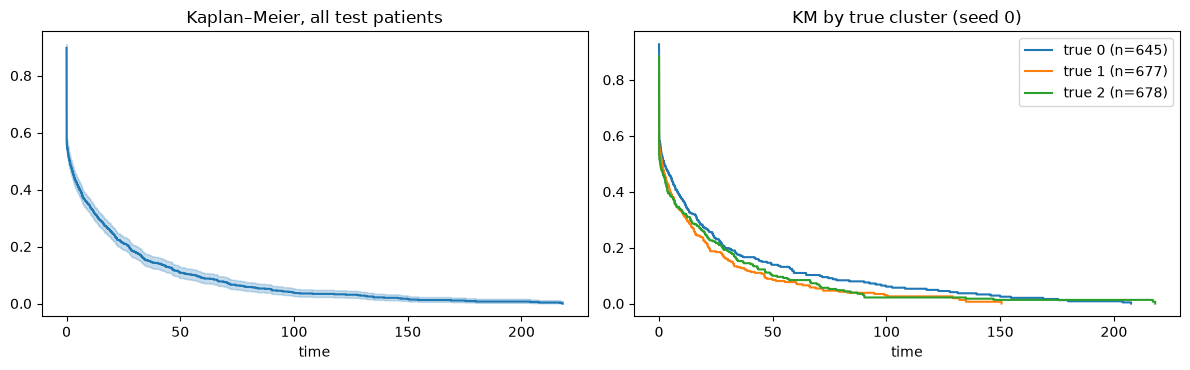

In [2]:
sim0 = load_simulated(n=N, p=P, k=K, d_lat=D_LAT, seed=0)
print(f"train {sim0.X_tr.shape}, val {sim0.X_va.shape}, test {sim0.X_te.shape}")
print(f"event rate {sim0.e_tr.mean():.1%} | median time {np.median(sim0.t_tr):.2f}")
print("true cluster sizes (test):", np.bincount(sim0.clusters_true_te).tolist())

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
KaplanMeierFitter().fit(sim0.t_te, sim0.e_te).plot_survival_function(ax=ax[0], legend=False)
ax[0].set(title="Kaplan–Meier, all test patients", xlabel="time")
for k in np.unique(sim0.clusters_true_te):
    m = sim0.clusters_true_te == k
    KaplanMeierFitter(label=f"true {k} (n={m.sum()})").fit(sim0.t_te[m], sim0.e_te[m]) \
        .plot_survival_function(ax=ax[1], ci_show=False)
ax[1].set(title="KM by true cluster (seed 0)", xlabel="time")
plt.tight_layout(); plt.show()


## Average over seeds

Each seed regenerates the dataset and retrains all models. Per-seed rows are appended to
`results/sim_by_seed.csv` after every seed.


In [3]:
rows = []

def fmt_metrics(m):
    """One-line summary for each model per seed."""
    parts = []
    for key, fmt in [
        ("C-index", "{:.3f}"),
        ("IBS", "{:.3f}"),
        ("ARI", "{:.3f}"),
        ("log-rank chi2", "{:.1f}"),
    ]:
        if key in m and m[key] == m[key]:  # present and not NaN
            parts.append(f"{key}={fmt.format(m[key])}")
    return " | ".join(parts) if parts else "(no metrics)"

for s in range(N_SEEDS):
    d = load_simulated(n=N, p=P, k=K, d_lat=D_LAT, seed=s)
    print(f"\n=== seed {s} | train {d.X_tr.shape} ===", flush=True)
    t_seed = time.time()

    print("  VaDeSC…", flush=True)
    t0 = time.time()
    m_v, cl_v, z_v = evaluate_vadesc(
        train_vadesc(d, K=K, d_lat=D_LAT, weibull_k=1.0, epochs=EPOCHS, seed=s, verbose=(s == 0)),
        d,
    )
    rows.append({"seed": s, "model": "VaDeSC", **m_v})
    print(f"    done in {(time.time() - t0) / 60:.1f} min | {fmt_metrics(m_v)}", flush=True)

    print("  VaDE…", flush=True)
    t0 = time.time()
    m_vd, cl_vd, _ = evaluate_vadesc(
        train_vadesc(d, K=K, d_lat=D_LAT, survival=False, epochs=EPOCHS, seed=s, verbose=False),
        d,
    )
    rows.append({"seed": s, "model": "VaDE", **m_vd})
    print(f"    done in {(time.time() - t0) / 60:.1f} min | {fmt_metrics(m_vd)}", flush=True)

    print("  k-means…", flush=True)
    t0 = time.time()
    cl_km = KMeans(K, n_init=10, random_state=s).fit(d.X_tr).predict(d.X_te)
    m_km = {
        "ARI": adjusted_rand_score(d.clusters_true_te, cl_km),
        "log-rank chi2": logrank_chi2(d, cl_km),
    }
    rows.append({"seed": s, "model": "k-means", **m_km})
    print(f"    done in {(time.time() - t0) / 60:.1f} min | {fmt_metrics(m_km)}", flush=True)

    for name, fn in [
        ("Cox PH", lambda: run_cox(d)),
        ("RSF", lambda: run_rsf(d, seed=s)),
        ("Weibull AFT", lambda: run_weibull_aft(d)),
    ]:
        print(f"  {name}…", flush=True)
        t0 = time.time()
        m = fn()
        rows.append({"seed": s, "model": name, **m})
        print(f"    done in {(time.time() - t0) / 60:.1f} min | {fmt_metrics(m)}", flush=True)

    # Persist after each seed
    by_seed = pd.DataFrame(rows)
    by_seed.to_csv(OUT / "sim_by_seed.csv", index=False)
    print(f"  seed {s} total {(time.time() - t_seed) / 60:.1f} min | saved {OUT / 'sim_by_seed.csv'}", flush=True)

    # Keep last seed for plots
    sim, clusters, z_te = d, cl_v, z_v

by_seed.round(3)



=== seed 0 | train (7000, 1000) ===


  VaDeSC…


epoch   25 | -ELBO   173.337 | val C-index 0.553 | ARI 0.037


epoch   50 | -ELBO   148.185 | val C-index 0.611 | ARI 0.062


epoch   75 | -ELBO   140.934 | val C-index 0.645 | ARI 0.111


epoch  100 | -ELBO   137.231 | val C-index 0.672 | ARI 0.142


... (101 outputs left out)

  Weibull AFT…


    done in 0.4 min | C-index=0.765 | IBS=0.180


  seed 4 total 30.2 min | saved ../results/sim_by_seed.csv


,seed,model,C-index,IBS,log-rank chi2,ARI
0,0,VaDeSC,0.813,0.144,2.901,0.448
1,0,VaDE,NaN,NaN,13.297,0.102
2,0,k-means,NaN,NaN,50.524,0.073
3,0,Cox PH,0.782,0.158,NaN,NaN
4,0,RSF,0.770,0.175,NaN,NaN
5,0,Weibull AFT,0.778,0.179,NaN,NaN
6,1,VaDeSC,0.745,0.171,58.623,0.319
7,1,VaDE,NaN,NaN,11.787,0.050
8,1,k-means,NaN,NaN,44.412,0.025
9,1,Cox PH,0.727,0.187,NaN,NaN


## Summary (mean ± std over seeds)


In [4]:
summary = by_seed.groupby("model")[["C-index", "IBS", "ARI", "log-rank chi2"]].agg(["mean", "std"])
summary = summary.reindex(["Cox PH", "RSF", "Weibull AFT", "VaDeSC", "VaDE", "k-means"])
summary.to_csv(OUT / "sim_summary.csv")
print("saved", OUT / "sim_summary.csv")
summary.round(3)


saved ../results/sim_summary.csv


C-index           IBS           ARI        log-rank chi2        
               mean    std   mean    std   mean    std          mean     std
model                                                                       
Cox PH        0.757  0.021  0.167  0.013    NaN    NaN           NaN     NaN
RSF           0.743  0.019  0.183  0.008    NaN    NaN           NaN     NaN
Weibull AFT   0.755  0.019  0.184  0.011    NaN    NaN           NaN     NaN
VaDeSC        0.773  0.035  0.156  0.013  0.323  0.105        24.291  22.967
VaDE            NaN    NaN    NaN    NaN  0.125  0.074        16.178   7.478
k-means         NaN    NaN    NaN    NaN  0.037  0.023        35.623  17.485

## Clusters (last seed)

VaDeSC predicted vs true clusters on the last finished seed.

seed 4 | ARI(VaDeSC, true) = 0.406 | log-rank chi2 = 4.8
label map (pred → true): {np.int64(0): np.int64(0), np.int64(1): np.int64(2), np.int64(2): np.int64(1)}


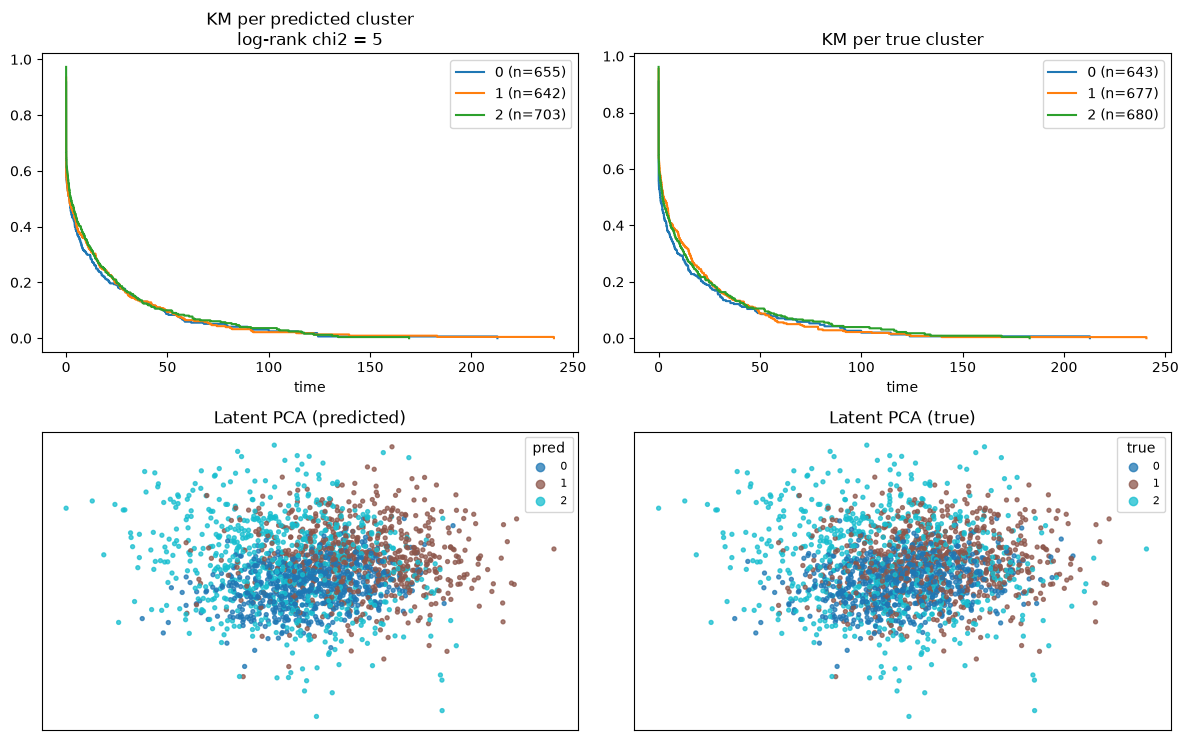

In [5]:
ari = adjusted_rand_score(sim.clusters_true_te, clusters)
print(f"seed {N_SEEDS - 1} | ARI(VaDeSC, true) = {ari:.3f} | log-rank chi2 = {logrank_chi2(sim, clusters):.1f}")

cont = pd.crosstab(clusters, sim.clusters_true_te)
r, c = linear_sum_assignment(-cont.to_numpy())
mapping = {cont.index[i]: cont.columns[j] for i, j in zip(r, c)}
clusters_plot = np.vectorize(mapping.get)(clusters)
print("label map (pred → true):", mapping)

fig, ax = plt.subplots(2, 2, figsize=(12, 7.5))

for k in np.unique(clusters_plot):
    m = clusters_plot == k
    KaplanMeierFitter(label=f"{k} (n={m.sum()})").fit(sim.t_te[m], sim.e_te[m]) \
        .plot_survival_function(ax=ax[0, 0], ci_show=False)
ax[0, 0].set(title=f"KM per predicted cluster\nlog-rank chi2 = {logrank_chi2(sim, clusters):.0f}",
             xlabel="time")

for k in np.unique(sim.clusters_true_te):
    m = sim.clusters_true_te == k
    KaplanMeierFitter(label=f"{k} (n={m.sum()})").fit(sim.t_te[m], sim.e_te[m]) \
        .plot_survival_function(ax=ax[0, 1], ci_show=False)
ax[0, 1].set(title="KM per true cluster", xlabel="time")

p2 = PCA(2).fit_transform(z_te)
sc0 = ax[1, 0].scatter(p2[:, 0], p2[:, 1], c=clusters_plot, s=8, cmap="tab10", alpha=0.75)
ax[1, 0].set(title="Latent PCA (predicted)", xticks=[], yticks=[])
ax[1, 0].legend(*sc0.legend_elements(), title="pred", loc="best", fontsize=8)

sc1 = ax[1, 1].scatter(p2[:, 0], p2[:, 1], c=sim.clusters_true_te, s=8, cmap="tab10", alpha=0.75)
ax[1, 1].set(title="Latent PCA (true)", xticks=[], yticks=[])
ax[1, 1].legend(*sc1.legend_elements(), title="true", loc="best", fontsize=8)

plt.tight_layout(); plt.show()